# Experiment 9: Implementation of K-Means Clustering

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

   Feature_1  Feature_2
0   6.319076   2.399619
1  -4.866968   9.753998
2  -8.849350   6.515994
3 -10.141604   6.056806
4  -7.410055  -6.115468


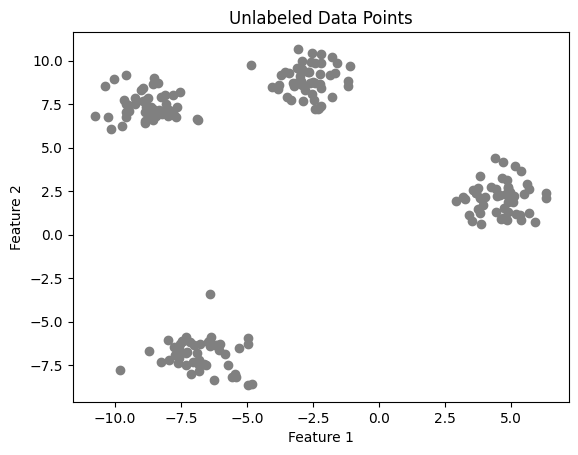

In [2]:
X, _ = make_blobs(n_samples=200, centers=4, cluster_std=0.9, random_state=42)
df = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])
print(df.head())
plt.scatter(X[:, 0], X[:, 1], color='gray')
plt.title('Unlabeled Data Points')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

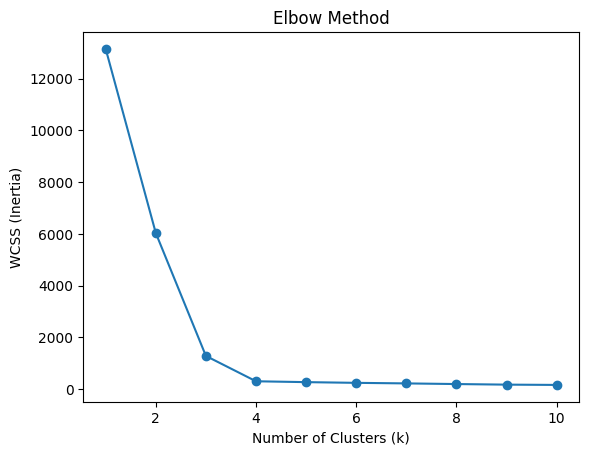

In [3]:
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.show()

In [4]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
labels = kmeans.fit_predict(X)
df['Cluster'] = labels
print(df['Cluster'].value_counts())

Cluster
0    50
1    50
3    50
2    50
Name: count, dtype: int64


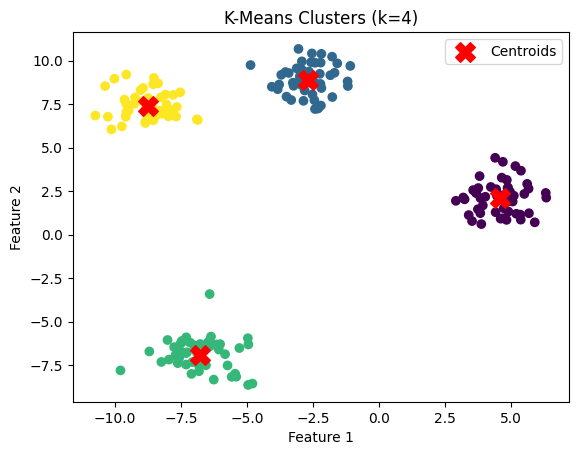

In [5]:
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis')
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, marker='X', label='Centroids')
plt.title('K-Means Clusters (k=4)')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.show()